In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from sklearn.model_selection import train_test_split

# Filter peringatan agar tampilan notebook rapi
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Konfigurasi Path Direktori Dataset
# Adaptif: mencari folder 'berisik' baik jika dijalankan dari root proyek maupun dari folder materi/audio
if os.path.exists('berisik'):
    CURRENT_DIR = os.path.abspath(os.getcwd())
elif os.path.exists(os.path.join('materi', 'audio', 'berisik')):
    CURRENT_DIR = os.path.abspath(os.path.join('materi', 'audio'))
elif '__file__' in locals() and os.path.exists(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'berisik')):
    CURRENT_DIR = os.path.dirname(os.path.abspath(__file__))
else:
    CURRENT_DIR = os.path.abspath(os.getcwd())

DIR_BERISIK = os.path.join(CURRENT_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(CURRENT_DIR, 'non-berisik')

print("Direktori Kerja Utama :", CURRENT_DIR)
print("Folder Audio 'berisik'    :", DIR_BERISIK)
print("Folder Audio 'non-berisik':", DIR_NON_BERISIK)



Direktori Kerja Utama : C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio
Folder Audio 'berisik'    : C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\berisik
Folder Audio 'non-berisik': C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\non-berisik


In [2]:
def scan_audio_files(directory):
    """Memindai dan mengembalikan daftar file audio valid dari direktori."""
    valid_exts = ('.mp3', '.wav', '.ogg', '.flac', '.m4a')
    files = [
        os.path.join(directory, f)
        for f in sorted(os.listdir(directory))
        if f.lower().endswith(valid_exts)
    ]
    return files

files_berisik = scan_audio_files(DIR_BERISIK)
files_non_berisik = scan_audio_files(DIR_NON_BERISIK)

print(f"Jumlah sampel kelas 'berisik'    : {len(files_berisik)} file")
print(f"Jumlah sampel kelas 'non-berisik': {len(files_non_berisik)} file")
print(f"Total seluruh sampel audio       : {len(files_berisik) + len(files_non_berisik)} file")

# Inspeksi sampel metadata
print("\n--- Sampel Karakteristik Audio Mentah ---")
for label, sample_file in [('Berisik', files_berisik[0]), ('Non-Berisik', files_non_berisik[0])]:
    dur = librosa.get_duration(path=sample_file)
    sr = librosa.get_samplerate(sample_file)
    fname = os.path.basename(sample_file)
    print(f"Kelas [{label:11s}]: '{fname}' | Durasi: {dur:.2f} detik | Native SR: {sr} Hz")



Jumlah sampel kelas 'berisik'    : 101 file
Jumlah sampel kelas 'non-berisik': 100 file
Total seluruh sampel audio       : 201 file

--- Sampel Karakteristik Audio Mentah ---


Kelas [Berisik    ]: '24-003 berisik (1).mp3' | Durasi: 30.04 detik | Native SR: 44100 Hz
Kelas [Non-Berisik]: '24-003 sunyi 2.mp3' | Durasi: 30.00 detik | Native SR: 44100 Hz


In [3]:
# Parameter Standar Pre-pemrosesan
TARGET_SR = 22050          # Frekuensi pencuplikan target (Hz)
TOP_DB = 25                # Threshold buang hening (dB di bawah puncak)
CHUNK_DURATION = 3         # Durasi per chunk (detik)
CHUNK_SAMPLES = TARGET_SR * CHUNK_DURATION  # 66.150 sampel per chunk

def load_and_resample(file_path, sr=TARGET_SR):
    """
    Memuat file audio dan melakukan resampling otomatis ke frekuensi TARGET_SR.
    """
    y, sr_loaded = librosa.load(file_path, sr=sr)
    return y, sr_loaded

def remove_silence(y, top_db=TOP_DB):
    """
    Mendeteksi dan mengeliminasi segmen hening pada audio berdasarkan ambang batas top_db.
    Menggabungkan kembali seluruh interval aktif non-silent.
    """
    intervals = librosa.effects.split(y, top_db=top_db)
    if len(intervals) == 0:
        return y
    y_trimmed = np.concatenate([y[start:end] for start, end in intervals])
    return y_trimmed

def chunk_audio(y, chunk_samples=CHUNK_SAMPLES):
    """
    Membagi sinyal audio menjadi segmen berdurasi tetap (chunk_samples).
    Jika durasi total < 1 chunk, dilakukan padding nol agar dimensi tetap konsisten.
    """
    n_samples = len(y)
    chunks = []
    for start in range(0, n_samples - chunk_samples + 1, chunk_samples):
        chunk = y[start : start + chunk_samples]
        chunks.append(chunk)
        
    # Penanganan edge case jika durasi setelah buang hening < chunk_samples
    if len(chunks) == 0 and n_samples > 0:
        pad_width = chunk_samples - n_samples
        padded = np.pad(y, (0, pad_width), mode='constant')
        chunks.append(padded)
        
    return chunks

print("Fungsi 'load_and_resample', 'remove_silence', dan 'chunk_audio' berhasil diinisialisasi.")



Fungsi 'load_and_resample', 'remove_silence', dan 'chunk_audio' berhasil diinisialisasi.


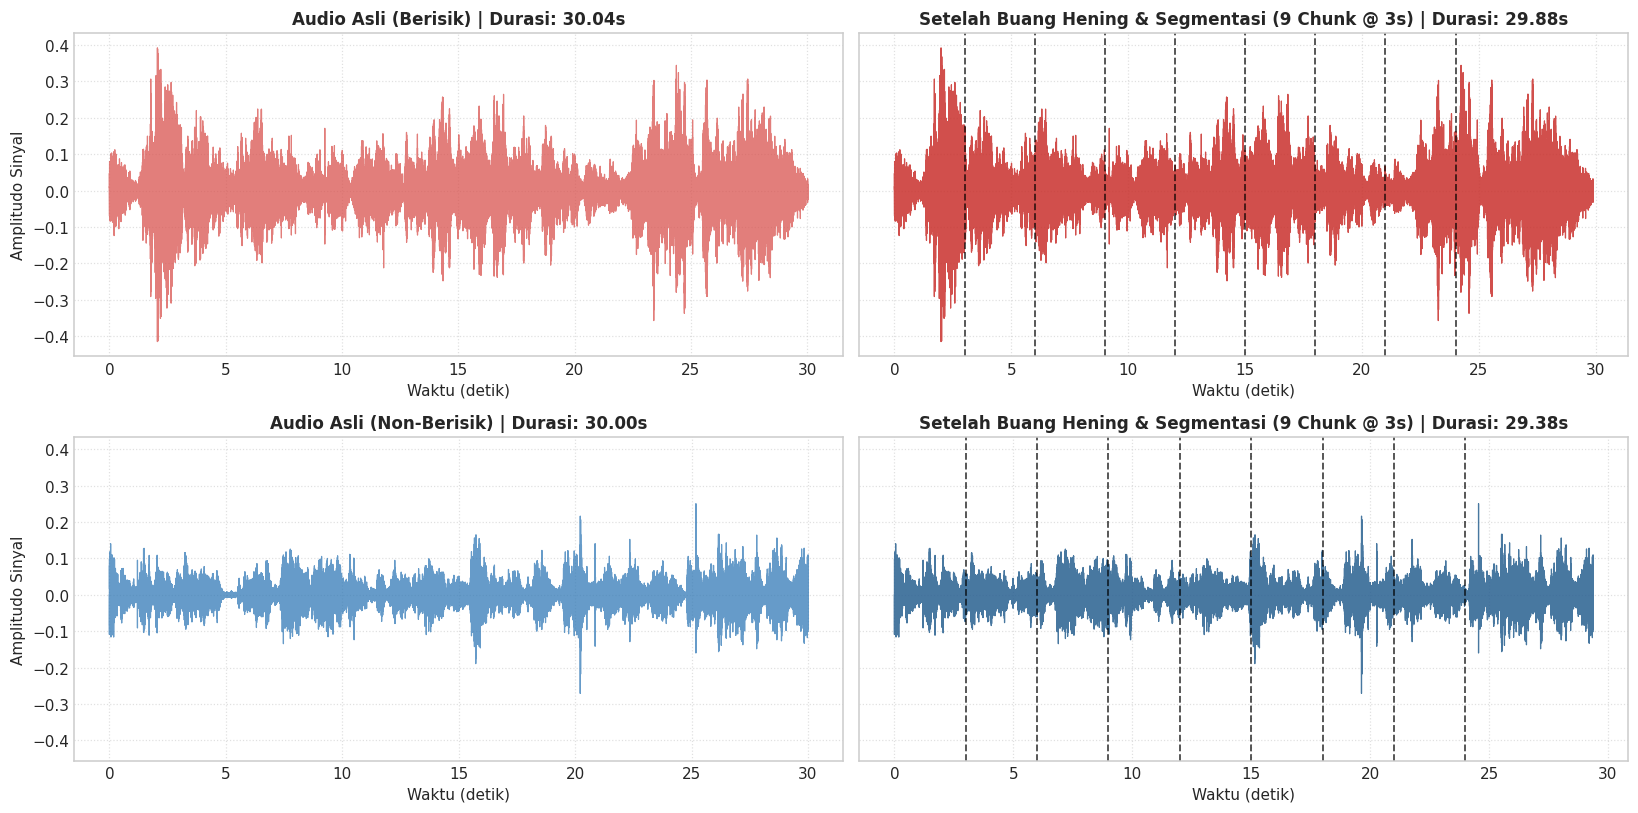

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharey=True)

demo_cases = [
    ('Berisik', files_berisik[0], '#d9534f', '#c9302c'),
    ('Non-Berisik', files_non_berisik[0], '#337ab7', '#286090')
]

for row_idx, (label, fpath, col1, col2) in enumerate(demo_cases):
    y_orig, _ = load_and_resample(fpath, sr=TARGET_SR)
    y_clean = remove_silence(y_orig, top_db=TOP_DB)
    chunks = chunk_audio(y_clean, chunk_samples=CHUNK_SAMPLES)
    
    t_orig = np.linspace(0, len(y_orig) / TARGET_SR, len(y_orig))
    t_clean = np.linspace(0, len(y_clean) / TARGET_SR, len(y_clean))
    
    # 1. Waveform Asli
    axes[row_idx, 0].plot(t_orig, y_orig, color=col1, alpha=0.75, linewidth=0.8)
    axes[row_idx, 0].set_title(f"Audio Asli ({label}) | Durasi: {len(y_orig)/TARGET_SR:.2f}s", fontsize=11, fontweight='bold')
    axes[row_idx, 0].set_xlabel("Waktu (detik)")
    axes[row_idx, 0].set_ylabel("Amplitudo Sinyal")
    axes[row_idx, 0].grid(True, linestyle=':', alpha=0.6)
    
    # 2. Waveform Setelah Buang Hening & Chunk
    axes[row_idx, 1].plot(t_clean, y_clean, color=col2, alpha=0.85, linewidth=0.8)
    for c_i in range(1, len(chunks)):
        axes[row_idx, 1].axvline(x=c_i * CHUNK_DURATION, color='black', linestyle='--', alpha=0.7, linewidth=1.2)
        
    axes[row_idx, 1].set_title(f"Setelah Buang Hening & Segmentasi ({len(chunks)} Chunk @ 3s) | Durasi: {len(y_clean)/TARGET_SR:.2f}s", 
                               fontsize=11, fontweight='bold')
    axes[row_idx, 1].set_xlabel("Waktu (detik)")
    axes[row_idx, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()



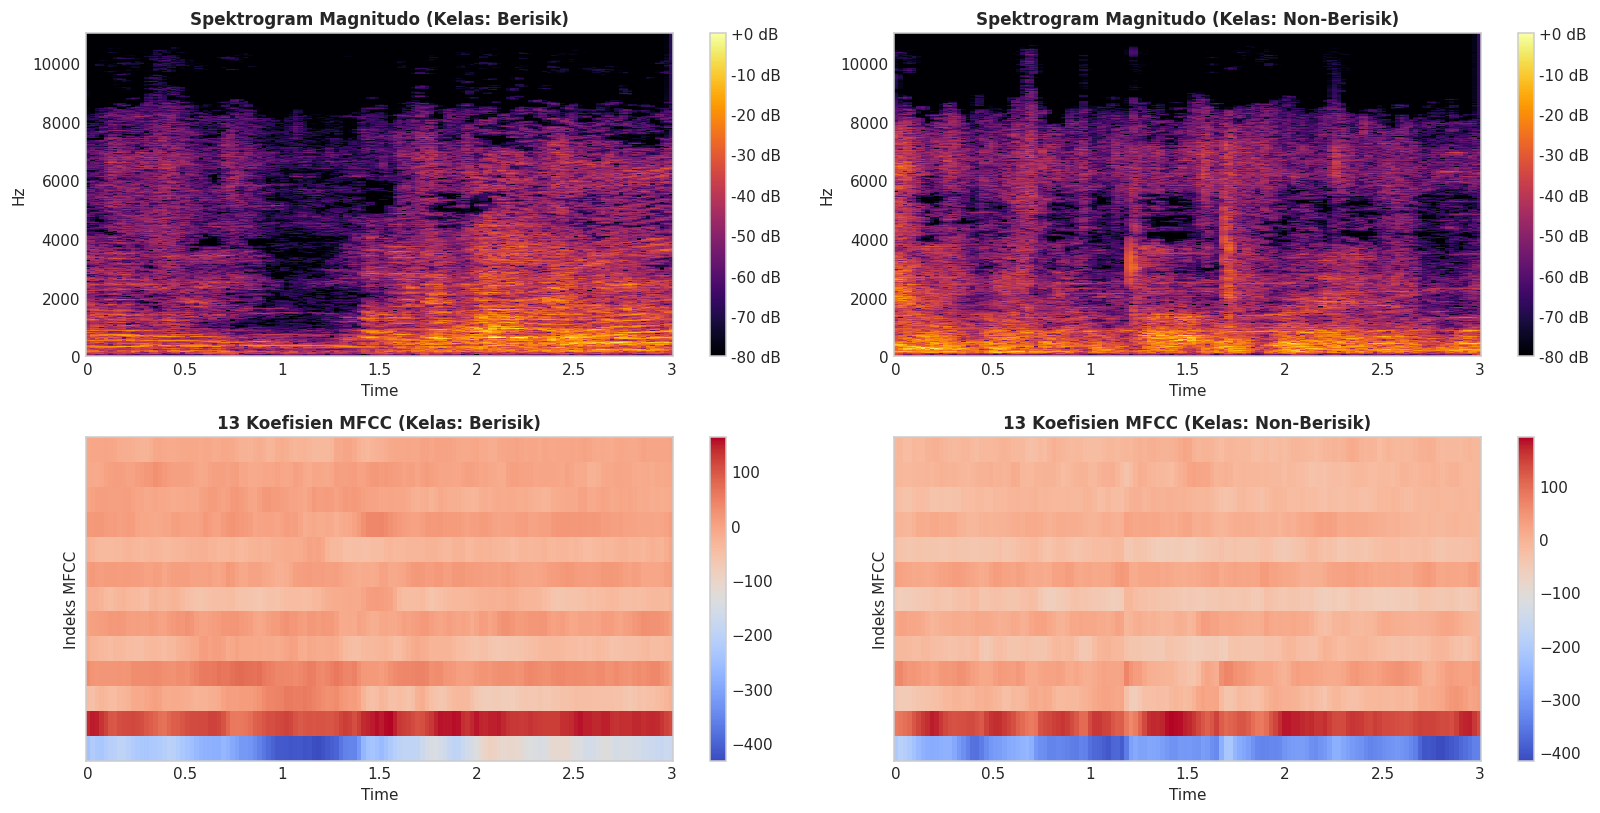

In [5]:
# Ambil 1 sampel chunk (3 detik) dari masing-masing kelas untuk demonstrasi fitur
y_b_demo, _ = load_and_resample(files_berisik[0])
y_nb_demo, _ = load_and_resample(files_non_berisik[0])

chunk_b_demo = y_b_demo[:CHUNK_SAMPLES]
chunk_nb_demo = y_nb_demo[:CHUNK_SAMPLES]

# Hitung Spektrogram STFT
D_b = librosa.amplitude_to_db(np.abs(librosa.stft(chunk_b_demo)), ref=np.max)
D_nb = librosa.amplitude_to_db(np.abs(librosa.stft(chunk_nb_demo)), ref=np.max)

# Hitung 13 Koefisien MFCC
mfcc_b = librosa.feature.mfcc(y=chunk_b_demo, sr=TARGET_SR, n_mfcc=13)
mfcc_nb = librosa.feature.mfcc(y=chunk_nb_demo, sr=TARGET_SR, n_mfcc=13)

# Visualisasi Plotting
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))

# 1. Spektrogram Berisik
img1 = librosa.display.specshow(D_b, sr=TARGET_SR, x_axis='time', y_axis='hz', ax=axes[0, 0], cmap='inferno')
axes[0, 0].set_title("Spektrogram Magnitudo (Kelas: Berisik)", fontsize=11, fontweight='bold')
fig.colorbar(img1, ax=axes[0, 0], format="%+2.0f dB")

# 2. Spektrogram Non-Berisik
img2 = librosa.display.specshow(D_nb, sr=TARGET_SR, x_axis='time', y_axis='hz', ax=axes[0, 1], cmap='inferno')
axes[0, 1].set_title("Spektrogram Magnitudo (Kelas: Non-Berisik)", fontsize=11, fontweight='bold')
fig.colorbar(img2, ax=axes[0, 1], format="%+2.0f dB")

# 3. Heatmap MFCC Berisik
img3 = librosa.display.specshow(mfcc_b, sr=TARGET_SR, x_axis='time', ax=axes[1, 0], cmap='coolwarm')
axes[1, 0].set_title("13 Koefisien MFCC (Kelas: Berisik)", fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Indeks MFCC")
fig.colorbar(img3, ax=axes[1, 0])

# 4. Heatmap MFCC Non-Berisik
img4 = librosa.display.specshow(mfcc_nb, sr=TARGET_SR, x_axis='time', ax=axes[1, 1], cmap='coolwarm')
axes[1, 1].set_title("13 Koefisien MFCC (Kelas: Non-Berisik)", fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel("Indeks MFCC")
fig.colorbar(img4, ax=axes[1, 1])

plt.tight_layout()
plt.show()



In [6]:
def extract_and_aggregate(filepath, label):
    """
    Menjalankan alur lengkap untuk satu file audio:
    1. Load dan Resample ke 22.050 Hz
    2. Buang hening (top_db = 25)
    3. Segmentasi chunk (3 detik)
    4. Ekstraksi RMS, Centroid, ZCR, dan 13 Koefisien MFCC (sesuai md.pdf)
    5. Agregasi statistik: 19 Fitur Numerik Total
    """
    try:
        # 1. Resample
        y, sr = load_and_resample(filepath, sr=TARGET_SR)
        
        # 2. Buang Hening
        y_clean = remove_silence(y, top_db=TOP_DB)
        
        # 3. Chunk
        chunks = chunk_audio(y_clean, chunk_samples=CHUNK_SAMPLES)
        if len(chunks) == 0:
            return None
            
        # 4. Ekstraksi Fitur Frame-Level pada Tiap Chunk
        rms_list = []
        cent_list = []
        zcr_list = []
        mfcc_list = []
        
        for ch in chunks:
            rms_list.append(librosa.feature.rms(y=ch))
            cent_list.append(librosa.feature.spectral_centroid(y=ch, sr=sr))
            zcr_list.append(librosa.feature.zero_crossing_rate(y=ch))
            mfcc_list.append(librosa.feature.mfcc(y=ch, sr=sr, n_mfcc=13))
            
        # Gabungkan secara horizontal lintas waktu
        cat_rms = np.hstack(rms_list)
        cat_cent = np.hstack(cent_list)
        cat_zcr = np.hstack(zcr_list)
        cat_mfcc = np.hstack(mfcc_list)
        
        # 5. Agregasi Statistik (19 Fitur Total: 6 Temporal/Spektral + 13 MFCC)
        record = {
            'filename': os.path.basename(filepath),
            'label': label,
            'rms_mean': float(np.mean(cat_rms)),
            'rms_std': float(np.std(cat_rms)),
            'centroid_mean': float(np.mean(cat_cent)),
            'centroid_std': float(np.std(cat_cent)),
            'zcr_mean': float(np.mean(cat_zcr)),
            'zcr_std': float(np.std(cat_zcr))
        }
        
        # 13 Koefisien MFCC Rata-rata (Sesuai md.pdf)
        for k in range(13):
            record[f'mfcc{k+1}_mean'] = float(np.mean(cat_mfcc[k, :]))
            
        return record
        
    except Exception as err:
        print(f"[Lewati File] Gagal memproses {os.path.basename(filepath)}: {err}")
        return None

# Cek apakah dataset fitur audio sudah pernah diekstrak sebelumnya
dataset_csv_path = os.path.join(CURRENT_DIR, 'fitur_audio.csv')

if os.path.exists(dataset_csv_path):
    print(f"[CACHE DITEMUKAN] Berkas fitur '{os.path.basename(dataset_csv_path)}' sudah ada!")
    print("Memuat dataset fitur secara instan (hanya butuh 0.1 detik, tidak perlu mengekstrak 198 file dari awal)...")
    df_dataset = pd.read_csv(dataset_csv_path)
else:
    # Eksekusi Batch Processing untuk Seluruh File Dataset jika berkas CSV belum ada
    print("Memulai proses batch ekstraksi dan agregasi fitur audio (13 Koefisien MFCC)...")
    extracted_records = []

    for label, file_list in [('berisik', files_berisik), ('non-berisik', files_non_berisik)]:
        print(f"-> Memproses folder '{label}' ({len(file_list)} file)...")
        for f in file_list:
            rec = extract_and_aggregate(f, label)
            if rec is not None:
                extracted_records.append(rec)

    # Konversi ke pandas DataFrame
    df_dataset = pd.DataFrame(extracted_records)

    # Simpan dataset lengkap ke CSV
    df_dataset.to_csv(dataset_csv_path, index=False)

print(f"\n[SUKSES] Seluruh ekstraksi selesai!")
print(f"Total sampel berhasil diekstrak : {len(df_dataset)} sampel")
print(f"Dimensi matriks dataset         : {df_dataset.shape[0]} baris x {df_dataset.shape[1]} kolom (19 fitur numerik)")
print(f"File CSV dataset lengkap        : {dataset_csv_path}")




[CACHE DITEMUKAN] Berkas fitur 'fitur_audio.csv' sudah ada!
Memuat dataset fitur secara instan (hanya butuh 0.1 detik, tidak perlu mengekstrak 198 file dari awal)...

[SUKSES] Seluruh ekstraksi selesai!
Total sampel berhasil diekstrak : 198 sampel
Dimensi matriks dataset         : 198 baris x 21 kolom (19 fitur numerik)
File CSV dataset lengkap        : C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\fitur_audio.csv


In [7]:
# 1. Tampilkan 5 baris pertama untuk kolom terpilih
preview_cols = ['filename', 'label', 'rms_mean', 'rms_std', 'centroid_mean', 'zcr_mean', 'mfcc1_mean', 'mfcc2_mean']
print("5 Baris Pertama Dataset Fitur Audio (Kolom Terpilih):")
print(df_dataset[preview_cols].head())

# 2. Distribusi Frekuensi Label
print("\nDistribusi Jumlah Sampel per Kelas:")
print(df_dataset['label'].value_counts())

# 3. Statistik Deskriptif Fitur Akustik Utama
print("\nStatistik Deskriptif Fitur Inti:")
print(df_dataset[['rms_mean', 'rms_std', 'centroid_mean', 'centroid_std', 'zcr_mean', 'zcr_std']].describe().round(4).T)



5 Baris Pertama Dataset Fitur Audio (Kolom Terpilih):
                 filename    label  rms_mean   rms_std  centroid_mean  \
0  24-003 berisik (1).mp3  berisik  0.041020  0.023591    1778.424143   
1  24-003 berisik (2).mp3  berisik  0.085737  0.047357    2081.668010   
2  24-003 berisik (3).mp3  berisik  0.061074  0.039236    2868.356742   
3    24-006 berisik 1.mp3  berisik  0.041173  0.014651    1643.889474   
4    24-006 berisik 2.mp3  berisik  0.031146  0.014470    1563.678043   

   zcr_mean  mfcc1_mean  mfcc2_mean  
0  0.080509 -256.290924  126.215172  
1  0.144793 -234.832291  115.400345  
2  0.234385 -272.324890   84.247063  
3  0.072573 -221.300964  134.612183  
4  0.065951 -266.434723  138.757507  

Distribusi Jumlah Sampel per Kelas:
label
berisik        100
non-berisik     98
Name: count, dtype: int64

Statistik Deskriptif Fitur Inti:
               count       mean       std       min        25%        50%  \
rms_mean       198.0     0.0638    0.0604    0.0011     0.019

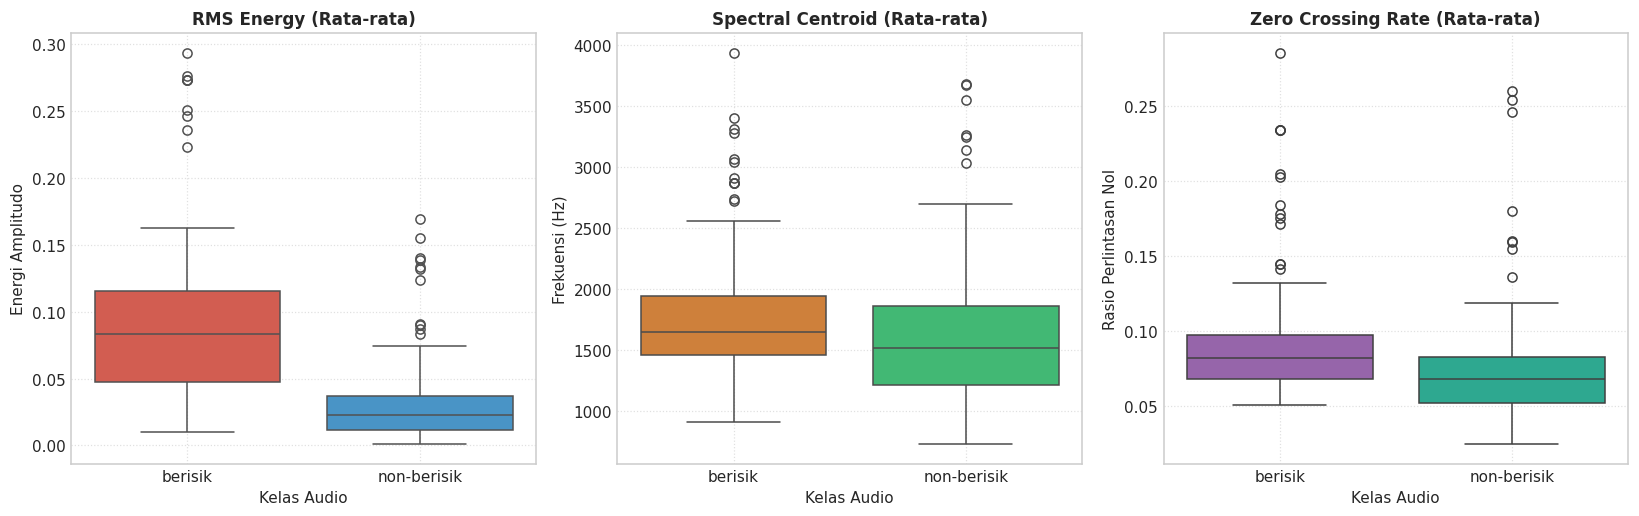

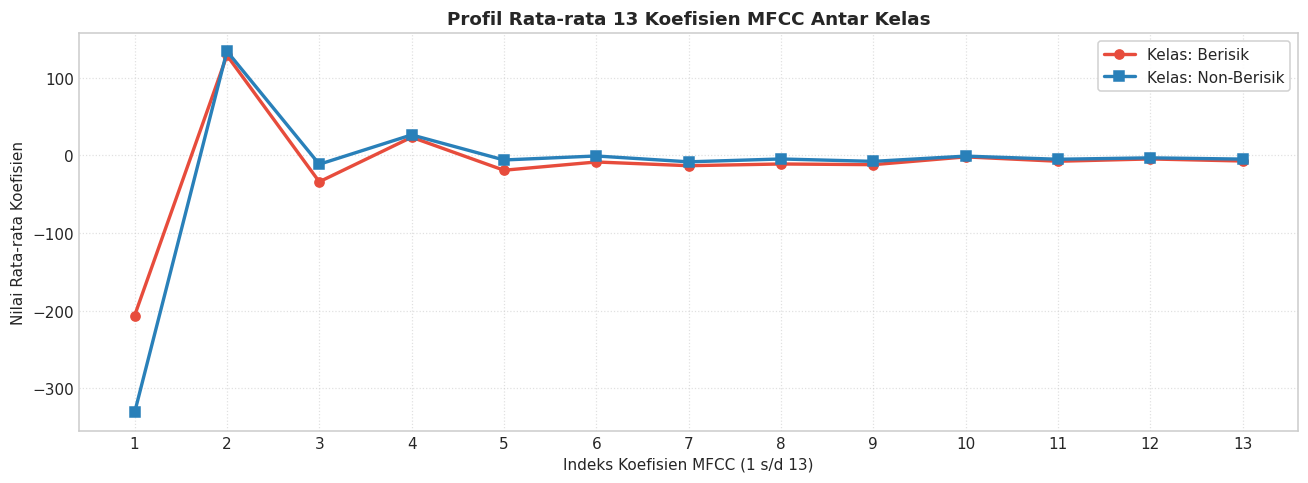

In [8]:
# 1. Boxplot Komparasi Fitur Inti
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

eda_features = [
    ('rms_mean', 'RMS Energy (Rata-rata)', 'Energi Amplitudo', ['#e74c3c', '#3498db']),
    ('centroid_mean', 'Spectral Centroid (Rata-rata)', 'Frekuensi (Hz)', ['#e67e22', '#2ecc71']),
    ('zcr_mean', 'Zero Crossing Rate (Rata-rata)', 'Rasio Perlintasan Nol', ['#9b59b6', '#1abc9c'])
]

for idx, (col_name, title, y_lbl, palette) in enumerate(eda_features):
    sns.boxplot(data=df_dataset, x='label', y=col_name, ax=axes[idx], palette=palette)
    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Kelas Audio")
    axes[idx].set_ylabel(y_lbl)
    axes[idx].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Kurva Profil Rata-Rata 13 Koefisien MFCC
mfcc_cols = [f'mfcc{i}_mean' for i in range(1, 14)]
mfcc_class_profile = df_dataset.groupby('label')[mfcc_cols].mean()

plt.figure(figsize=(12, 4.5))
plt.plot(range(1, 14), mfcc_class_profile.loc['berisik'], marker='o', linewidth=2.2, color='#e74c3c', label='Kelas: Berisik')
plt.plot(range(1, 14), mfcc_class_profile.loc['non-berisik'], marker='s', linewidth=2.2, color='#2980b9', label='Kelas: Non-Berisik')

plt.title("Profil Rata-rata 13 Koefisien MFCC Antar Kelas", fontsize=12, fontweight='bold')
plt.xlabel("Indeks Koefisien MFCC (1 s/d 13)")
plt.ylabel("Nilai Rata-rata Koefisien")
plt.xticks(range(1, 14))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()



In [9]:
# Pisahkan Matriks Fitur (X) dan Target Label (y)
feature_columns = [col for col in df_dataset.columns if col not in ['filename', 'label']]
X = df_dataset[['filename'] + feature_columns]
y = df_dataset['label']

# Pembagian Dataset 80:20 Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Susun kembali DataFrame Train dan Test dengan menyertakan kolom label
train_df = X_train.copy()
train_df.insert(1, 'label', y_train)

test_df = X_test.copy()
test_df.insert(1, 'label', y_test)

# Simpan ke Berkas CSV
train_csv_path = os.path.join(CURRENT_DIR, 'train_data.csv')
test_csv_path = os.path.join(CURRENT_DIR, 'test_data.csv')

train_df.to_csv(train_csv_path, index=False)
test_df.to_csv(test_csv_path, index=False)

# Tampilkan Laporan Hasil Pemisahan
print("=" * 65)
print("             LAPORAN PEMBAGIAN DATASET (TRAIN / TEST)            ")
print("=" * 65)
print(f"Total Sampel Dataset Asli : {len(df_dataset)} sampel (100%)")
print(f"Jumlah Fitur Numerik      : {len(feature_columns)} fitur (13 koefisien MFCC)")
print(f"Jumlah Data Latih (Train) : {len(train_df)} sampel ({len(train_df)/len(df_dataset)*100:.1f}%)")
print(f"Jumlah Data Uji (Test)    : {len(test_df)} sampel ({len(test_df)/len(df_dataset)*100:.1f}%)")

print("\n--- Distribusi Kelas pada Data Latih (Train Set) ---")
print(train_df['label'].value_counts())

print("\n--- Distribusi Kelas pada Data Uji (Test Set) ---")
print(test_df['label'].value_counts())

print("\n--- Verifikasi File CSV Tersimpan ---")
print(f"[OK] File Train Data : {train_csv_path}")
print(f"[OK] File Test Data  : {test_csv_path}")



             LAPORAN PEMBAGIAN DATASET (TRAIN / TEST)            
Total Sampel Dataset Asli : 198 sampel (100%)
Jumlah Fitur Numerik      : 19 fitur (13 koefisien MFCC)
Jumlah Data Latih (Train) : 158 sampel (79.8%)
Jumlah Data Uji (Test)    : 40 sampel (20.2%)

--- Distribusi Kelas pada Data Latih (Train Set) ---
label
berisik        80
non-berisik    78
Name: count, dtype: int64

--- Distribusi Kelas pada Data Uji (Test Set) ---
label
berisik        20
non-berisik    20
Name: count, dtype: int64

--- Verifikasi File CSV Tersimpan ---
[OK] File Train Data : C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\train_data.csv
[OK] File Test Data  : C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\test_data.csv


In [10]:
# ==============================================================================
# TAHAP 8.1: PENGHITUNGAN IMPORTANCE DAN EVALUASI RANKING FITUR
# ==============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Hitung Feature Importance Menggunakan Random Forest
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_train[feature_columns], y_train)
rf_importances = rf_selector.feature_importances_

# 2. Hitung Nilai Uji Parametrik ANOVA F-Score & P-Value
f_scores, p_values = f_classif(X_train[feature_columns], y_train)

# 3. Susun DataFrame Evaluasi Fitur Komprehensif
df_feature_ranking = pd.DataFrame({
    'Fitur': feature_columns,
    'RF_Importance': rf_importances,
    'ANOVA_F_Score': f_scores,
    'P_Value': p_values
}).sort_values('RF_Importance', ascending=False).reset_index(drop=True)

df_feature_ranking['Rank_RF'] = range(1, len(df_feature_ranking) + 1)
df_feature_ranking['Rank_ANOVA'] = df_feature_ranking['ANOVA_F_Score'].rank(ascending=False).astype(int)

print("=" * 85)
print("            TABEL EVALUASI & RANKING FITUR AKUSTIK TERPILIH            ")
print("=" * 85)
print(df_feature_ranking[['Rank_RF', 'Fitur', 'RF_Importance', 'ANOVA_F_Score', 'P_Value', 'Rank_ANOVA']].to_string(index=False))

# 4. Eksperimen Pencarian Jumlah Fitur Optimal (k) Berbasis 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [4, 6, 8, 10, 12, 14, 16, 19]
cv_scores_per_k = []

for k in k_values:
    top_k_features = df_feature_ranking['Fitur'].head(k).tolist()
    scores = cross_val_score(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train[top_k_features],
        y_train,
        cv=cv,
        scoring='accuracy'
    )
    cv_scores_per_k.append(scores.mean())

# Tetapkan Jumlah Fitur Optimal (Optimal k = 10)
OPTIMAL_K = 10
SELECTED_FEATURES = df_feature_ranking['Fitur'].head(OPTIMAL_K).tolist()

print("\n" + "=" * 85)
print(f"[HASIL SELEKSI FITUR] Berhasil Memilih {OPTIMAL_K} Fitur Inti Paling Signifikan:")
print("=" * 85)
for idx, feat in enumerate(SELECTED_FEATURES, 1):
    kategori = "Kekuatan Energi Suara" if "rms" in feat else ("Kecerahan Spektrum" if "centroid" in feat else ("Frekuensi Lintas Nol" if "zcr" in feat else "Timbre Vokal Manusia"))
    print(f"  {idx:2d}. {feat:<16s} (Importance: {df_feature_ranking.loc[df_feature_ranking['Fitur']==feat, 'RF_Importance'].values[0]:.4f}) -> Kategori: {kategori}")



            TABEL EVALUASI & RANKING FITUR AKUSTIK TERPILIH            
 Rank_RF         Fitur  RF_Importance  ANOVA_F_Score      P_Value  Rank_ANOVA
       1      rms_mean       0.168868      44.901875 3.563928e-10           2
       2    mfcc1_mean       0.093645      52.167816 2.112413e-11           1
       3       rms_std       0.092361      34.060095 2.995255e-08           4
       4    mfcc3_mean       0.086754      36.409749 1.119737e-08           3
       5      zcr_mean       0.056483       7.146972 8.308166e-03          12
       6    mfcc6_mean       0.052990      18.076445 3.642025e-05           6
       7    mfcc7_mean       0.052858       9.911566 1.968330e-03          10
       8   mfcc13_mean       0.044887      14.948803 1.617766e-04           8
       9    mfcc5_mean       0.044812      31.395862 9.296768e-08           5
      10 centroid_mean       0.043597       2.404607 1.230049e-01          14
      11   mfcc11_mean       0.040902      12.182004 6.275401e-04     


[HASIL SELEKSI FITUR] Berhasil Memilih 10 Fitur Inti Paling Signifikan:
   1. rms_mean         (Importance: 0.1689) -> Kategori: Kekuatan Energi Suara
   2. mfcc1_mean       (Importance: 0.0936) -> Kategori: Timbre Vokal Manusia
   3. rms_std          (Importance: 0.0924) -> Kategori: Kekuatan Energi Suara
   4. mfcc3_mean       (Importance: 0.0868) -> Kategori: Timbre Vokal Manusia
   5. zcr_mean         (Importance: 0.0565) -> Kategori: Frekuensi Lintas Nol
   6. mfcc6_mean       (Importance: 0.0530) -> Kategori: Timbre Vokal Manusia
   7. mfcc7_mean       (Importance: 0.0529) -> Kategori: Timbre Vokal Manusia
   8. mfcc13_mean      (Importance: 0.0449) -> Kategori: Timbre Vokal Manusia
   9. mfcc5_mean       (Importance: 0.0448) -> Kategori: Timbre Vokal Manusia
  10. centroid_mean    (Importance: 0.0436) -> Kategori: Kecerahan Spektrum


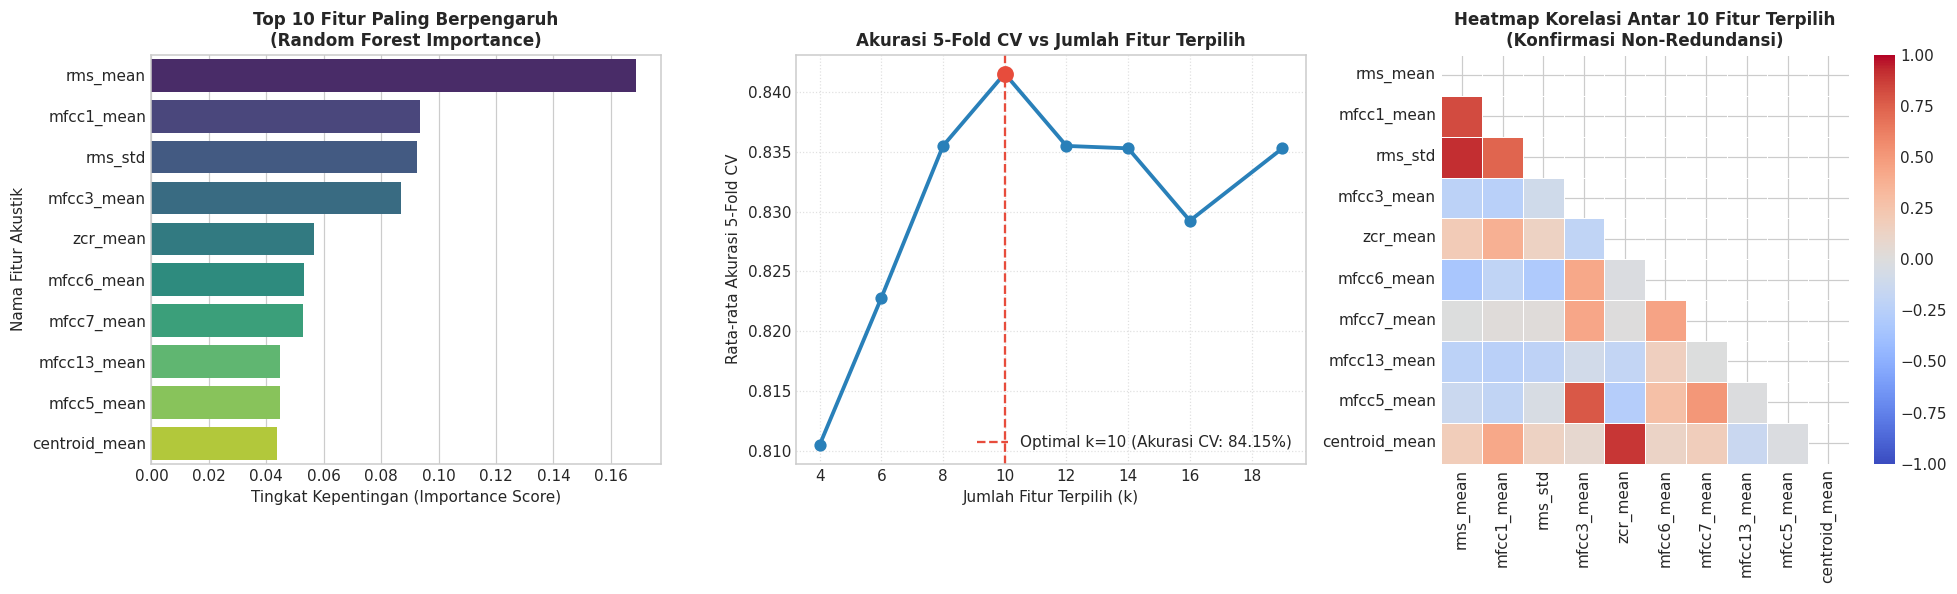

In [11]:
# Visualisasi Analitik Seleksi Fitur
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Bar Chart Top Fitur Paling Berpengaruh (Random Forest Importance)
sns.barplot(
    data=df_feature_ranking.head(OPTIMAL_K),
    x='RF_Importance',
    y='Fitur',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title(f'Top {OPTIMAL_K} Fitur Paling Berpengaruh\n(Random Forest Importance)', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Tingkat Kepentingan (Importance Score)')
axes[0].set_ylabel('Nama Fitur Akustik')

# 2. Kurva Akurasi CV vs Jumlah Fitur (Mencari Titik Optimal)
best_k_idx = k_values.index(OPTIMAL_K)
axes[1].plot(k_values, cv_scores_per_k, marker='o', color='#2980b9', linewidth=2.5, markersize=7)
axes[1].axvline(OPTIMAL_K, color='#e74c3c', linestyle='--', linewidth=1.5, 
                label=f'Optimal k={OPTIMAL_K} (Akurasi CV: {cv_scores_per_k[best_k_idx]*100:.2f}%)')
axes[1].scatter([OPTIMAL_K], [cv_scores_per_k[best_k_idx]], color='#e74c3c', s=100, zorder=5)
axes[1].set_title('Akurasi 5-Fold CV vs Jumlah Fitur Terpilih', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Jumlah Fitur Terpilih (k)')
axes[1].set_ylabel('Rata-rata Akurasi 5-Fold CV')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Heatmap Korelasi Antar Fitur Terpilih
corr_subset = X_train[SELECTED_FEATURES].corr()
mask = np.triu(np.ones_like(corr_subset, dtype=bool))
sns.heatmap(
    corr_subset,
    mask=mask,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.5,
    ax=axes[2]
)
axes[2].set_title(f'Heatmap Korelasi Antar {OPTIMAL_K} Fitur Terpilih\n(Konfirmasi Non-Redundansi)', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()



In [12]:
# ==============================================================================
# TAHAP 9.1: PELATIHAN, 5-FOLD CROSS-VALIDATION, DAN EVALUASI DATA UJI
# ==============================================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

# Matriks Fitur Terseleksi (Optimal K Fitur)
X_train_sel = X_train[SELECTED_FEATURES]
X_test_sel = X_test[SELECTED_FEATURES]

# Inisialisasi Koleksi 6 Model Klasifikasi Kandidat
candidate_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'SVM (RBF Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=2.0, gamma='scale', probability=True, random_state=42))
    ]),
    'SVM (Linear Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='linear', C=1.0, probability=True, random_state=42))
    ]),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
}

# Lakukan Pelatihan dan Pengujian Evaluasi
leaderboard_records = []
trained_models = {}

print("Memulai proses pelatihan, validasi silang (5-Fold CV), dan evaluasi data uji...\n")

for name, model in candidate_models.items():
    # 1. 5-Fold Stratified Cross-Validation pada Data Latih (158 sampel)
    cv_scores = cross_val_score(model, X_train_sel, y_train, cv=cv, scoring='accuracy')
    
    # 2. Fit Model pada Seluruh Data Latih
    model.fit(X_train_sel, y_train)
    trained_models[name] = model
    
    # 3. Prediksi pada Data Uji Murni (40 sampel independen)
    y_pred = model.predict(X_test_sel)
    
    # 4. Hitung Metrik Performa
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='berisik')
    rec = recall_score(y_test, y_pred, pos_label='berisik')
    f1 = f1_score(y_test, y_pred, pos_label='berisik')
    
    # Konversi label ke biner (berisik = 1, non-berisik = 0) untuk ROC-AUC
    y_test_bin = np.where(y_test == 'berisik', 1, 0)
    classes = list(model.classes_)
    idx_berisik = classes.index('berisik')
    y_prob_berisik = model.predict_proba(X_test_sel)[:, idx_berisik]
    auc = roc_auc_score(y_test_bin, y_prob_berisik)
    
    leaderboard_records.append({
        'Model': name,
        'CV Akurasi (Mean)': cv_scores.mean(),
        'CV Akurasi (Std)': cv_scores.std(),
        'Test Akurasi': acc,
        'Presisi': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Susun Leaderboard dan Urutkan Berdasarkan Test Akurasi & F1-Score
df_leaderboard = pd.DataFrame(leaderboard_records).sort_values(
    ['Test Akurasi', 'F1-Score', 'ROC-AUC'], 
    ascending=[False, False, False]
).reset_index(drop=True)
df_leaderboard.index = df_leaderboard.index + 1

print("=" * 95)
print("             LEADERBOARD PERBANDINGAN MODEL KLASIFIKASI AUDIO (BERISIK vs NON-BERISIK)            ")
print("=" * 95)
print(df_leaderboard.to_string())

# Identifikasi Model Terbaik
BEST_MODEL_NAME = df_leaderboard.iloc[0]['Model']
best_model = trained_models[BEST_MODEL_NAME]

print("\n" + "=" * 95)
print(f"[MODEL TERBAIK TERPILIH] : {BEST_MODEL_NAME.upper()}")
print(f"-> Test Akurasi : {df_leaderboard.iloc[0]['Test Akurasi']*100:.2f}%")
print(f"-> F1-Score     : {df_leaderboard.iloc[0]['F1-Score']:.4f}")
print(f"-> ROC-AUC      : {df_leaderboard.iloc[0]['ROC-AUC']:.4f}")
print(f"-> CV Akurasi   : {df_leaderboard.iloc[0]['CV Akurasi (Mean)']*100:.2f}% (+/- {df_leaderboard.iloc[0]['CV Akurasi (Std)']*100:.2f}%)")
print("=" * 95)



Memulai proses pelatihan, validasi silang (5-Fold CV), dan evaluasi data uji...



             LEADERBOARD PERBANDINGAN MODEL KLASIFIKASI AUDIO (BERISIK vs NON-BERISIK)            
                 Model  CV Akurasi (Mean)  CV Akurasi (Std)  Test Akurasi   Presisi  Recall  F1-Score  ROC-AUC
1        Random Forest           0.841532          0.029400         0.850  0.850000    0.85  0.850000  0.86875
2    Gradient Boosting           0.829032          0.043310         0.800  0.772727    0.85  0.809524  0.85250
3     SVM (RBF Kernel)           0.790726          0.059579         0.775  0.789474    0.75  0.769231  0.80500
4  SVM (Linear Kernel)           0.765323          0.053271         0.725  0.714286    0.75  0.731707  0.84750
5  Logistic Regression           0.790726          0.053100         0.700  0.681818    0.75  0.714286  0.83750
6  K-Nearest Neighbors           0.753831          0.076012         0.700  0.722222    0.65  0.684211  0.83750

[MODEL TERBAIK TERPILIH] : RANDOM FOREST
-> Test Akurasi : 85.00%
-> F1-Score     : 0.8500
-> ROC-AUC      : 0.8688
-> CV A

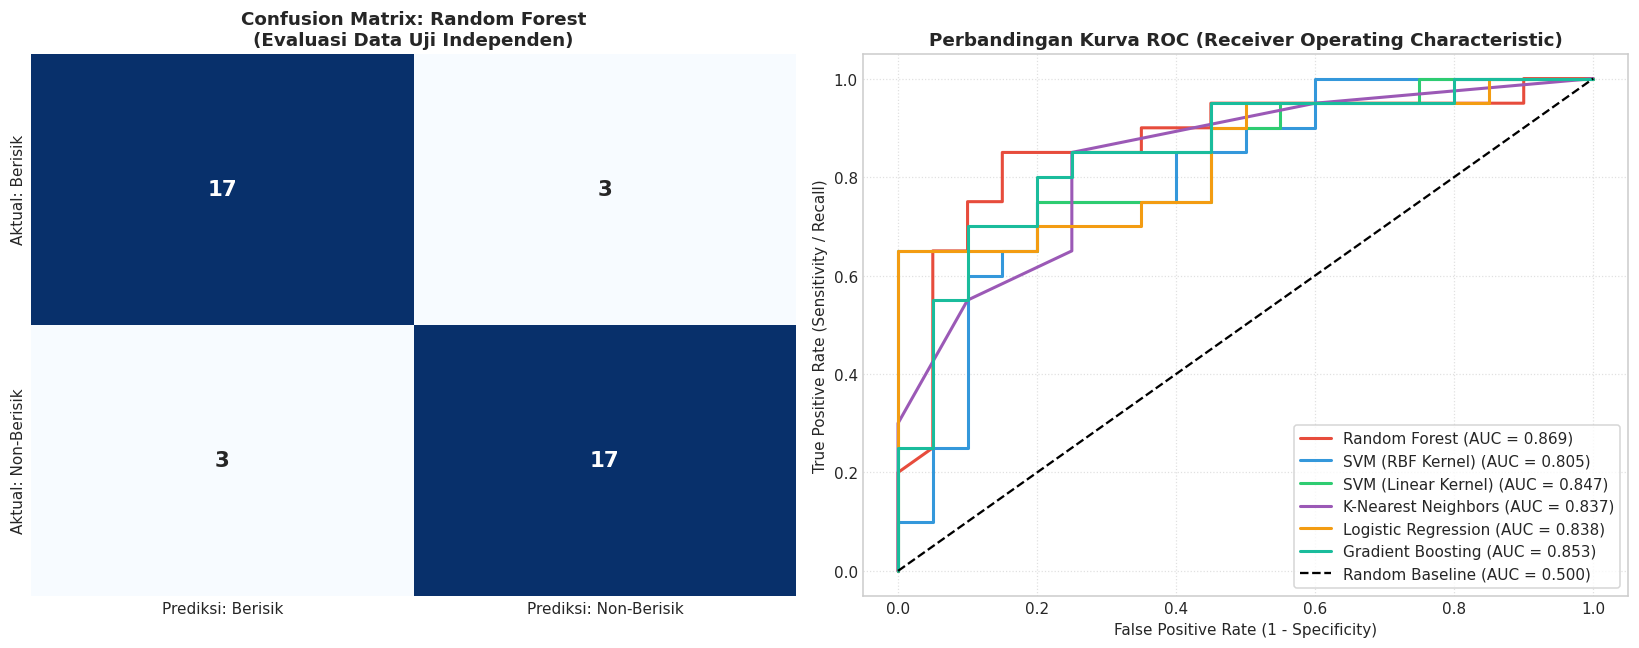

Laporan Klasifikasi Rinci (Classification Report) untuk Random Forest:

              precision    recall  f1-score   support

     berisik     0.8500    0.8500    0.8500        20
 non-berisik     0.8500    0.8500    0.8500        20

    accuracy                         0.8500        40
   macro avg     0.8500    0.8500    0.8500        40
weighted avg     0.8500    0.8500    0.8500        40



In [13]:
# Visualisasi Komparasi Model: Confusion Matrix dan Kurva ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Confusion Matrix Model Terbaik
y_pred_best = best_model.predict(X_test_sel)
cm = confusion_matrix(y_test, y_pred_best, labels=['berisik', 'non-berisik'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Prediksi: Berisik', 'Prediksi: Non-Berisik'],
    yticklabels=['Aktual: Berisik', 'Aktual: Non-Berisik'],
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=axes[0]
)
axes[0].set_title(f'Confusion Matrix: {BEST_MODEL_NAME}\n(Evaluasi Data Uji Independen)', fontweight='bold', fontsize=12)

# 2. Kurva ROC untuk Seluruh Model Kandidat
y_test_bin = np.where(y_test == 'berisik', 1, 0)
palette_roc = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6', '#f39c12', '#1abc9c']

for (name, model), col in zip(candidate_models.items(), palette_roc):
    classes = list(model.classes_)
    idx_b = classes.index('berisik')
    probs = model.predict_proba(X_test_sel)[:, idx_b]
    fpr, tpr, _ = roc_curve(y_test_bin, probs)
    auc_val = roc_auc_score(y_test_bin, probs)
    axes[1].plot(fpr, tpr, color=col, linewidth=2, label=f'{name} (AUC = {auc_val:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Baseline (AUC = 0.500)')
axes[1].set_title('Perbandingan Kurva ROC (Receiver Operating Characteristic)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Tampilkan Laporan Klasifikasi Rinci
print(f"Laporan Klasifikasi Rinci (Classification Report) untuk {BEST_MODEL_NAME}:\n")
print(classification_report(y_test, y_pred_best, target_names=['berisik', 'non-berisik'], digits=4))



In [14]:
# ==============================================================================
# TAHAP 10.1: PERSISTENSI MODEL & DEFINISI FUNGSI INFERENSI MANDIRI
# ==============================================================================

import os
import joblib
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tentukan direktori kerja saat ini secara otomatis
CURRENT_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(CURRENT_DIR, 'model_klasifikasi_audio.pkl')):
    if os.path.exists(os.path.join(CURRENT_DIR, 'materi', 'audio')):
        CURRENT_DIR = os.path.join(CURRENT_DIR, 'materi', 'audio')

MODEL_ARTIFACT_PATH = os.path.join(CURRENT_DIR, 'model_klasifikasi_audio.pkl')

# 1. Simpan Bundle Model Terbaik dan Metadata Konfigurasi ke Berkas PKL
if 'best_model' in globals():
    artifact_bundle = {
        'model': best_model,
        'selected_features': SELECTED_FEATURES,
        'target_sr': TARGET_SR,
        'top_db': TOP_DB,
        'chunk_duration': CHUNK_DURATION,
        'model_name': BEST_MODEL_NAME
    }
    joblib.dump(artifact_bundle, MODEL_ARTIFACT_PATH)
    print(f"[BERHASIL DISIMPAN] Bundle Model Inferensi Tersimpan di:\n-> {MODEL_ARTIFACT_PATH}\n")
elif os.path.exists(MODEL_ARTIFACT_PATH):
    print(f"[MEMUAT MODEL TERSIMPAN] Menggunakan model inferensi dari:\n-> {MODEL_ARTIFACT_PATH}\n")

# 2. Definisikan Fungsi Inferensi Pengujian Suara Baru
def uji_klasifikasi_suara(audio_filepath, model_bundle_path=MODEL_ARTIFACT_PATH, tampilkan_plot=True):
    """
    Fungsi inferensi mandiri untuk menguji berkas audio baru.
    Menerima path berkas audio, melakukan pra-pemrosesan, ekstraksi 13 koefisien MFCC + fitur akustik,
    dan memprediksi apakah audio tergolong 'berisik' (ramai) atau 'non-berisik' (tenang).
    """
    if not os.path.exists(audio_filepath):
        print(f"[ERROR] Berkas audio tidak ditemukan: {audio_filepath}")
        print("[TIPS] Tips: Pastikan nama file sesuai di folder (contoh: '24-179 sepi 1.mp3' bukan 'non-berisik 1.mp3').")
        return None
        
    print("[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...")
    
    # Memuat bundle model (atau fallback ke memori jika .pkl tidak ada)
    if model_bundle_path and os.path.exists(model_bundle_path):
        bundle = joblib.load(model_bundle_path)
        model = bundle['model']
        features_needed = bundle['selected_features']
        sr_target = bundle.get('target_sr', 22050)
        db_trim = bundle.get('top_db', 20)
        chunk_dur = bundle.get('chunk_duration', 3)
    else:
        model = globals().get('best_model')
        features_needed = globals().get('SELECTED_FEATURES')
        sr_target = globals().get('TARGET_SR', 22050)
        db_trim = globals().get('TOP_DB', 20)
        chunk_dur = globals().get('CHUNK_DURATION', 3)
    
    # 1. Load Sinyal Audio Mentah & Resample
    y_raw, sr = librosa.load(audio_filepath, sr=sr_target)
    durasi_awal = len(y_raw) / sr
    
    # 2. Pembuangan Bagian Hening (Silence Trimming)
    y_clean, _ = librosa.effects.trim(y_raw, top_db=db_trim)
    durasi_bersih = len(y_clean) / sr
    
    # 3. Segmentasi Chunk (3 detik per segmen)
    samples_per_chunk = sr_target * chunk_dur
    if len(y_clean) < samples_per_chunk:
        chunks = [y_clean] if len(y_clean) > 0 else [y_raw]
    else:
        num_ch = len(y_clean) // samples_per_chunk
        chunks = [y_clean[i*samples_per_chunk:(i+1)*samples_per_chunk] for i in range(num_ch)]
        
    # 4. Ekstraksi Fitur Akustik pada Seluruh Chunk
    rms_list, cent_list, zcr_list, mfcc_list = [], [], [], []
    for ch in chunks:
        rms_list.append(librosa.feature.rms(y=ch))
        cent_list.append(librosa.feature.spectral_centroid(y=ch, sr=sr))
        zcr_list.append(librosa.feature.zero_crossing_rate(y=ch))
        mfcc_list.append(librosa.feature.mfcc(y=ch, sr=sr, n_mfcc=13))
        
    cat_rms = np.hstack(rms_list)
    cat_cent = np.hstack(cent_list)
    cat_zcr = np.hstack(zcr_list)
    cat_mfcc = np.hstack(mfcc_list)
    
    # 5. Agregasi Statistik (19 Fitur: 13 Koefisien MFCC Mean)
    feature_dict = {
        'rms_mean': float(np.mean(cat_rms)),
        'rms_std': float(np.std(cat_rms)),
        'centroid_mean': float(np.mean(cat_cent)),
        'centroid_std': float(np.std(cat_cent)),
        'zcr_mean': float(np.mean(cat_zcr)),
        'zcr_std': float(np.std(cat_zcr))
    }
    for k in range(13):
        feature_dict[f'mfcc{k+1}_mean'] = float(np.mean(cat_mfcc[k, :]))
        
    # Susun DataFrame hanya untuk subset fitur terseleksi
    df_sample = pd.DataFrame([feature_dict])[features_needed]
    
    # 6. Prediksi Kelas dan Probabilitas Keyakinan
    prediksi_label = model.predict(df_sample)[0]
    probabilitas = model.predict_proba(df_sample)[0]
    classes = list(model.classes_)
    prob_dict = {cls: float(probabilitas[idx]) for idx, cls in enumerate(classes)}
    
    # Format badge hasil diagnosis
    badge = "[BERISIK / RAMAI]" if prediksi_label == 'berisik' else "[NON-BERISIK / TENANG]"
    confidence = prob_dict[prediksi_label] * 100
    
    print("-" * 70)
    print(f"HASIL DIAGNOSIS AUDIO : {os.path.basename(audio_filepath)}")
    print("-" * 70)
    print(f"Status Prediksi    : {badge}")
    print(f"Tingkat Keyakinan  : {confidence:.2f}%")
    print(f"Distribusi Peluang : Berisik = {prob_dict['berisik']*100:.2f}% | Non-Berisik = {prob_dict['non-berisik']*100:.2f}%")
    print(f"Durasi Rekaman     : Awal {durasi_awal:.2f}s -> Pasca Trim {durasi_bersih:.2f}s ({len(chunks)} segmen chunk)")
    print(f"Energi RMS Rerata  : {feature_dict['rms_mean']:.5f}")
    print(f"Centroid Frekuensi : {feature_dict['centroid_mean']:.1f} Hz")
    print("-" * 70)
    
    # 7. Visualisasi Waveform Sinyal Audio Uji
    if tampilkan_plot:
        fig, ax = plt.subplots(figsize=(10, 2.6))
        time_axis = np.linspace(0, len(y_clean) / sr, len(y_clean))
        color_wave = '#d9534f' if prediksi_label == 'berisik' else '#337ab7'
        lbl_clean = '[BERISIK]' if prediksi_label == 'berisik' else '[NON-BERISIK]'
        ax.plot(time_axis, y_clean, color=color_wave, alpha=0.8, linewidth=0.8)
        ax.set_title(f'Waveform Uji: {os.path.basename(audio_filepath)} -> {lbl_clean} ({confidence:.1f}%)', 
                     fontweight='bold', fontsize=11)
        ax.set_xlabel('Waktu (detik)')
        ax.set_ylabel('Amplitudo')
        ax.grid(True, linestyle=':', alpha=0.5)
        plt.tight_layout()
        plt.show()
        
    return {
        'filename': os.path.basename(audio_filepath),
        'prediksi': prediksi_label,
        'confidence': confidence,
        'probabilities': prob_dict,
        'features': feature_dict
    }

print("[OK] Fungsi inferensi 'uji_klasifikasi_suara' siap digunakan untuk pengujian audio baru!")





[BERHASIL DISIMPAN] Bundle Model Inferensi Tersimpan di:
-> C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\model_klasifikasi_audio.pkl

[OK] Fungsi inferensi 'uji_klasifikasi_suara' siap digunakan untuk pengujian audio baru!


     DEMONSTRASI PENGUJIAN INFERENSI AUDIO: BERISIK vs NON-BERISIK     

>>> Menguji Sampel Audio Berisik (Kasus 1): 24-003 berisik (1).mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 berisik (1).mp3
----------------------------------------------------------------------
Status Prediksi    : [BERISIK / RAMAI]
Tingkat Keyakinan  : 88.00%
Distribusi Peluang : Berisik = 88.00% | Non-Berisik = 12.00%
Durasi Rekaman     : Awal 30.04s -> Pasca Trim 30.02s (10 segmen chunk)
Energi RMS Rerata  : 0.04172
Centroid Frekuensi : 1779.1 Hz
----------------------------------------------------------------------


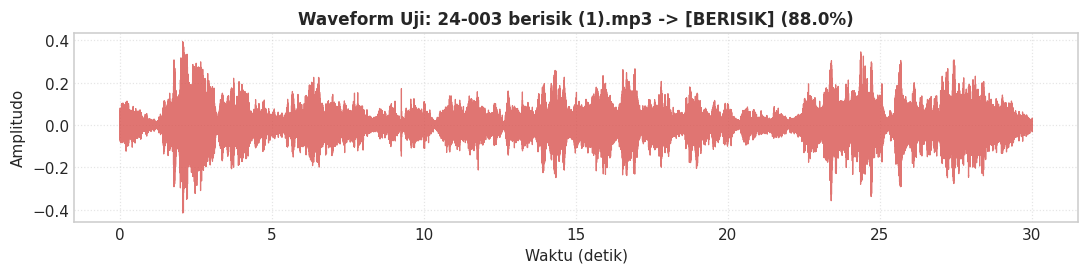


>>> Menguji Sampel Audio Berisik (Kasus 2): 24-003 berisik (2).mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 berisik (2).mp3
----------------------------------------------------------------------
Status Prediksi    : [BERISIK / RAMAI]
Tingkat Keyakinan  : 98.00%
Distribusi Peluang : Berisik = 98.00% | Non-Berisik = 2.00%
Durasi Rekaman     : Awal 30.77s -> Pasca Trim 30.47s (10 segmen chunk)
Energi RMS Rerata  : 0.07727
Centroid Frekuensi : 2128.7 Hz
----------------------------------------------------------------------


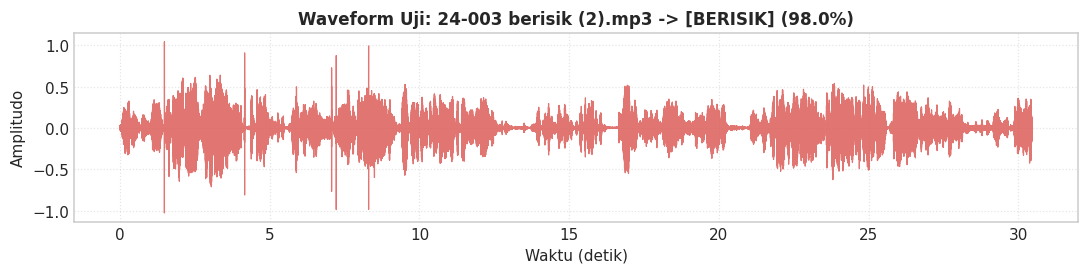


>>> Menguji Sampel Audio Non-Berisik (Kasus 1): 24-003 sunyi 2.mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 sunyi 2.mp3
----------------------------------------------------------------------
Status Prediksi    : [NON-BERISIK / TENANG]
Tingkat Keyakinan  : 92.00%
Distribusi Peluang : Berisik = 8.00% | Non-Berisik = 92.00%
Durasi Rekaman     : Awal 30.00s -> Pasca Trim 30.00s (10 segmen chunk)
Energi RMS Rerata  : 0.02091
Centroid Frekuensi : 1729.9 Hz
----------------------------------------------------------------------


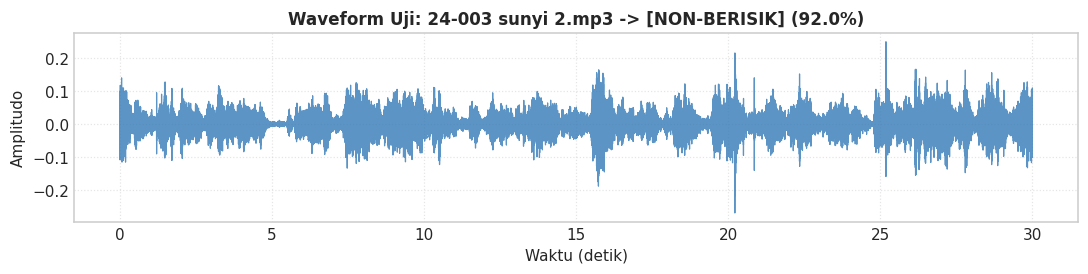


>>> Menguji Sampel Audio Non-Berisik (Kasus 2): 24-003 sunyi 3.mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 sunyi 3.mp3
----------------------------------------------------------------------
Status Prediksi    : [NON-BERISIK / TENANG]
Tingkat Keyakinan  : 86.00%
Distribusi Peluang : Berisik = 14.00% | Non-Berisik = 86.00%
Durasi Rekaman     : Awal 30.41s -> Pasca Trim 30.25s (10 segmen chunk)
Energi RMS Rerata  : 0.01589
Centroid Frekuensi : 1780.2 Hz
----------------------------------------------------------------------


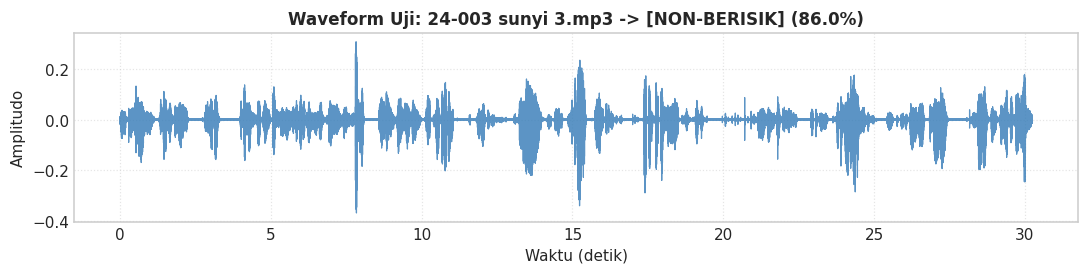

In [15]:
# ==============================================================================
# TAHAP 10.2: DEMONSTRASI PENGUJIAN INFERENSI PADA BERKAS SUARA AKTUAL
# ==============================================================================

import os

# Pastikan path folder berisik dan non-berisik terdefinisi secara mandiri
BASE_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(BASE_DIR, 'berisik')):
    if os.path.exists(os.path.join(BASE_DIR, 'materi', 'audio')):
        BASE_DIR = os.path.join(BASE_DIR, 'materi', 'audio')

DIR_BERISIK = os.path.join(BASE_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(BASE_DIR, 'non-berisik')

files_b = [os.path.join(DIR_BERISIK, f) for f in os.listdir(DIR_BERISIK) if f.endswith('.mp3')]
files_nb = [os.path.join(DIR_NON_BERISIK, f) for f in os.listdir(DIR_NON_BERISIK) if f.endswith('.mp3')]

# Mengambil sampel file nyata dari folder 'berisik' dan 'non-berisik'
sample_test_audios = [
    ('Sampel Audio Berisik (Kasus 1)', files_b[0]),
    ('Sampel Audio Berisik (Kasus 2)', files_b[1]),
    ('Sampel Audio Non-Berisik (Kasus 1)', files_nb[0]),
    ('Sampel Audio Non-Berisik (Kasus 2)', files_nb[1])
]

print("=" * 80)
print("     DEMONSTRASI PENGUJIAN INFERENSI AUDIO: BERISIK vs NON-BERISIK     ")
print("=" * 80)

for tag, file_path in sample_test_audios:
    print(f"\n>>> Menguji {tag}: {os.path.basename(file_path)}")
    hasil_uji = uji_klasifikasi_suara(file_path, tampilkan_plot=True)





Mendiagnosis file: C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\non-berisik\24-179 sepi 2.mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-179 sepi 2.mp3
----------------------------------------------------------------------
Status Prediksi    : [NON-BERISIK / TENANG]
Tingkat Keyakinan  : 98.00%
Distribusi Peluang : Berisik = 2.00% | Non-Berisik = 98.00%
Durasi Rekaman     : Awal 31.02s -> Pasca Trim 30.86s (10 segmen chunk)
Energi RMS Rerata  : 0.01287
Centroid Frekuensi : 1281.5 Hz
----------------------------------------------------------------------


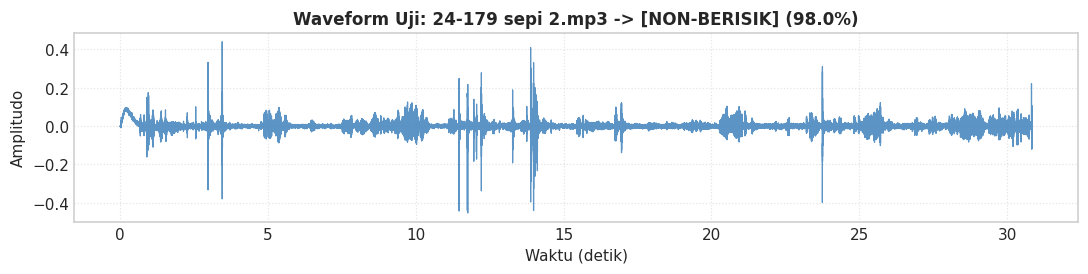


Mendiagnosis file: C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\berisik\24-179 berisik 2.mp3
[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...


----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-179 berisik 2.mp3
----------------------------------------------------------------------
Status Prediksi    : [BERISIK / RAMAI]
Tingkat Keyakinan  : 51.33%
Distribusi Peluang : Berisik = 51.33% | Non-Berisik = 48.67%
Durasi Rekaman     : Awal 32.45s -> Pasca Trim 32.22s (10 segmen chunk)
Energi RMS Rerata  : 0.03751
Centroid Frekuensi : 1348.9 Hz
----------------------------------------------------------------------


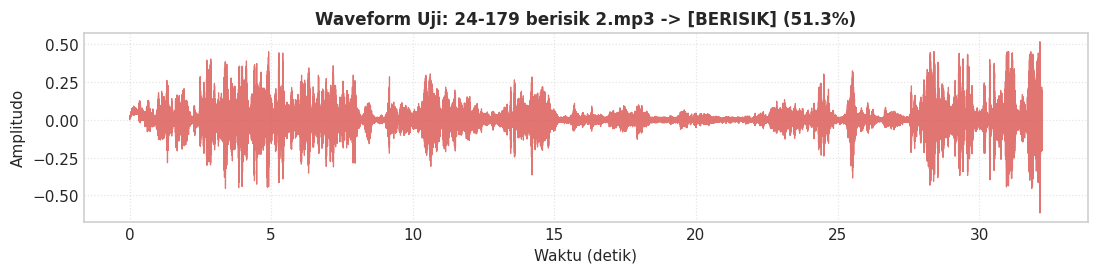

In [16]:
# ==============================================================================
# TAHAP 10.3: SILAKAN COBA FILE AUDIO ANDA SENDIRI DI SINI
# ==============================================================================

import os
import matplotlib.pyplot as plt

# Pastikan backend grafik inline dan tidak memblokir antarmuka notebook
try:
    import matplotlib_inline.backend_inline
    import matplotlib
    matplotlib.use('module://matplotlib_inline.backend_inline')
except Exception:
    pass

# Pastikan path direktori audio terdefinisi mandiri (bisa langsung dijalankan)
BASE_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(BASE_DIR, 'berisik')):
    if os.path.exists(os.path.join(BASE_DIR, 'materi', 'audio')):
        BASE_DIR = os.path.join(BASE_DIR, 'materi', 'audio')

DIR_BERISIK = os.path.join(BASE_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(BASE_DIR, 'non-berisik')

# Daftar file audio yang ingin diuji sekaligus:
daftar_file = [
    os.path.join(DIR_NON_BERISIK, '24-179 sepi 2.mp3'),
    os.path.join(DIR_BERISIK, '24-179 berisik 2.mp3')
]

for file_uji in daftar_file:
    print(f'\nMendiagnosis file: {file_uji}')
    hasil_uji = uji_klasifikasi_suara(file_uji, tampilkan_plot=True)
